<a href="https://colab.research.google.com/github/isisbia/am_turma5_prova/blob/main/ProvaML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROVA PRÁTICA 13 - PREDIÇÃO DA DIREÇÃO DO PREÇO DA IBM
## Módulo V: Inteligência de Mercado Financeiro

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# 1. Requisição a API Alpha Vantage

In [2]:
url_av = "https://www.alphavantage.co/query"

params = {
    "function": "TIME_SERIES_DAILY",
    "symbol": "IBM",
    "apikey": "663MT6223VT9NZ1T",
    "datatype": "json",
    "outputsize": "compact"
}

try:
    response = requests.get(
        url_av,
        params=params,
        timeout=30
    )
    response.raise_for_status()
    res = response.json()

except requests.exceptions.RequestException as e:
    raise RuntimeError(
        f"Erro na requisicao a Alpha Vantage: {e}"
    )

time_series = res.get("Time Series (Daily)", {})

if not time_series:
    raise ValueError(
        f"A API nao retornou cotacoes. Resposta: {res}"
    )

print("Cotacoes recebidas com sucesso!")
print("Quantidade de registros:", len(time_series))


Cotacoes recebidas com sucesso!
Quantidade de registros: 100


# 2. Construção do Dataframe

In [3]:
df_stock = pd.DataFrame.from_dict(
    time_series,
    orient="index"
)

df_stock.columns = [
    "open", "high", "low", "close", "volume"
]

df_stock = df_stock.astype(float)
df_stock.index = pd.to_datetime(df_stock.index)
df_stock = df_stock.sort_index()


# 3. Engenharia de Features

In [4]:
df_stock["return_today"] = (
    (df_stock["close"] - df_stock["open"])
    / df_stock["open"]
)

df_stock["amplitude"] = (
    (df_stock["high"] - df_stock["low"])
    / df_stock["open"]
)


# 4. Criação do target: fechamento do próximo pregão


In [5]:
close_next = df_stock["close"].shift(-1)

df_stock["target_direction"] = np.where(
    close_next.isna(),
    np.nan,
    (close_next > df_stock["close"]).astype(int)
)

# Remove somente a linha sem target valido
df_stock = df_stock.dropna(
    subset=["target_direction"]
).copy()

df_stock["target_direction"] = (
    df_stock["target_direction"].astype(int)
)

# 5. Seleção das features e do target

In [6]:
X_stock = df_stock[
    ["return_today", "amplitude", "volume"]
].copy()

y_stock = df_stock["target_direction"].copy()


# 6. Divisão temporal

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_stock,
    y_stock,
    test_size=0.20,
    shuffle=False
)


# 7. Categorização do volume, One-hot encoder e Standardscaler



## 7.1. Define as categorias de volume usando somente o treino

In [8]:
_, bins_volume = pd.qcut(
    X_train["volume"],
    q=3,
    retbins=True,
    duplicates="drop"
)

if len(bins_volume) != 4:
    raise ValueError(
        "Nao foi possivel criar tres faixas distintas "
        "de volume. Verifique os dados da API."
    )

bins_volume[0] = -np.inf
bins_volume[-1] = np.inf

nomes_categorias = ["Baixo", "Medio", "Alto"]

X_train = X_train.copy()
X_test = X_test.copy()

# Aplica os mesmos limites ao treino e ao teste

X_train["volume_cat"] = pd.cut(
    X_train["volume"],
    bins=bins_volume,
    labels=nomes_categorias,
    include_lowest=True
)

X_test["volume_cat"] = pd.cut(
    X_test["volume"],
    bins=bins_volume,
    labels=nomes_categorias,
    include_lowest=True
)

if X_train["volume_cat"].isna().any():
    raise ValueError("Existem categorias de volume vazias no treino.")

if X_test["volume_cat"].isna().any():
    raise ValueError("Existem categorias de volume vazias no teste.")

## 7.2. Separa as features numéricas e categóricas


In [9]:
X_train_numeric = X_train[
    ["return_today", "amplitude"]
]

X_test_numeric = X_test[
    ["return_today", "amplitude"]
]

X_train_volume = X_train[["volume_cat"]]
X_test_volume = X_test[["volume_cat"]]

## 7.3. Codifica as categorias com OneHotEncoder


In [10]:
encoder = OneHotEncoder(
    categories=[nomes_categorias],
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(X_train_volume)
X_test_encoded = encoder.transform(X_test_volume)

volume_columns = encoder.get_feature_names_out(
    ["volume_cat"]
)

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=volume_columns,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=volume_columns,
    index=X_test.index
)

## 7.4. Padroniza as features numéricas


In [11]:
scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(
    X_train_numeric
)

X_test_num_scaled = scaler.transform(
    X_test_numeric
)

X_train_num_scaled = pd.DataFrame(
    X_train_num_scaled,
    columns=["return_today", "amplitude"],
    index=X_train.index
)

X_test_num_scaled = pd.DataFrame(
    X_test_num_scaled,
    columns=["return_today", "amplitude"],
    index=X_test.index
)

## 7.5. Junta as features numéricas e categóricas


In [12]:
X_train_final = pd.concat(
    [X_train_num_scaled, X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test_num_scaled, X_test_encoded],
    axis=1
)

print("\nPreparacao das features concluida!")
print("Formato do treino:", X_train_final.shape)
print("Formato do teste:", X_test_final.shape)
print("Features:", list(X_train_final.columns))


Preparacao das features concluida!
Formato do treino: (79, 5)
Formato do teste: (20, 5)
Features: ['return_today', 'amplitude', 'volume_cat_Baixo', 'volume_cat_Medio', 'volume_cat_Alto']


# 8. Treinamento do GaussianNB

In [13]:
gnb_stock = GaussianNB()

gnb_stock.fit(
    X_train_final,
    y_train
)

GaussianNB()

# 9. Previsões

In [14]:
y_pred_stock = gnb_stock.predict(X_test_final)

# 10. Métricas de avaliação

In [15]:
accuracy = accuracy_score(y_test, y_pred_stock)

cm = confusion_matrix(
    y_test,
    y_pred_stock,
    labels=[0, 1]
)

report = classification_report(
    y_test,
    y_pred_stock,
    labels=[0, 1],
    target_names=["Queda/Estavel", "Alta"],
    zero_division=0
)

# 11. Modelo de referência (baseline)

In [16]:
classe_majoritaria = y_train.mode()[0]

y_baseline = np.full(
    len(y_test),
    classe_majoritaria
)

baseline_accuracy = accuracy_score(
    y_test,
    y_baseline
)

ganho_baseline = accuracy - baseline_accuracy

# 12. Apresentação dos resultados

In [17]:
print("\n" + "=" * 65)
print("PROVA PRÁTICA 13 - PREDICAO DA DIREÇÃO DA IBM")
print("=" * 65)

print("\nPERÍODO DOS DADOS")
print("-" * 65)
print("Primeira data:", df_stock.index.min().date())
print("Ultima data:  ", df_stock.index.max().date())

print("\nTAMANHO DA AMOSTRA")
print("-" * 65)
print("Total de amostras:", len(df_stock))
print("Treinamento:      ", len(X_train))
print("Teste:            ", len(X_test))

print("\nDISTRIBUIÇÃO DO TARGET")
print("-" * 65)

target_distribution = (
    df_stock["target_direction"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Queda/Estável",
        1: "Alta"
    })
)

print(target_distribution)

print("\nFEATURES UTILIZADAS")
print("-" * 65)
print(list(X_train_final.columns))

print("\nRESULTADO DO GAUSSIANNB")
print("-" * 65)
print(f"Acurácia: {accuracy:.4f}")
print(f"Acurácia percentual: {accuracy * 100:.2f}%")

print("\nBASELINE")
print("-" * 65)
print("Classe majoritária:", classe_majoritaria)
print(f"Acurácia do baseline: {baseline_accuracy:.4f}")
print(f"Acurácia do baseline: {baseline_accuracy * 100:.2f}%")
print(
    f"Ganho sobre o baseline: "
    f"{ganho_baseline * 100:.2f} pontos percentuais"
)

print("\nMATRIZ DE CONFUSÃO")
print("-" * 65)
print(cm)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("-" * 65)
print(report)

print("=" * 65)



PROVA PRÁTICA 13 - PREDICAO DA DIREÇÃO DA IBM

PERÍODO DOS DADOS
-----------------------------------------------------------------
Primeira data: 2026-05-20
Ultima data:   2026-10-09

TAMANHO DA AMOSTRA
-----------------------------------------------------------------
Total de amostras: 99
Treinamento:       79
Teste:             20

DISTRIBUIÇÃO DO TARGET
-----------------------------------------------------------------
target_direction
Queda/Estável    50
Alta             49
Name: count, dtype: int64

FEATURES UTILIZADAS
-----------------------------------------------------------------
['return_today', 'amplitude', 'volume_cat_Baixo', 'volume_cat_Medio', 'volume_cat_Alto']

RESULTADO DO GAUSSIANNB
-----------------------------------------------------------------
Acurácia: 0.5000
Acurácia percentual: 50.00%

BASELINE
-----------------------------------------------------------------
Classe majoritária: 1
Acurácia do baseline: 0.3000
Acurácia do baseline: 30.00%
Ganho sobre o baseline:

# 15. Gráficos para análise dos resultados

# GRÁFICO 1 - Evolução do preço de fechamento da IBM

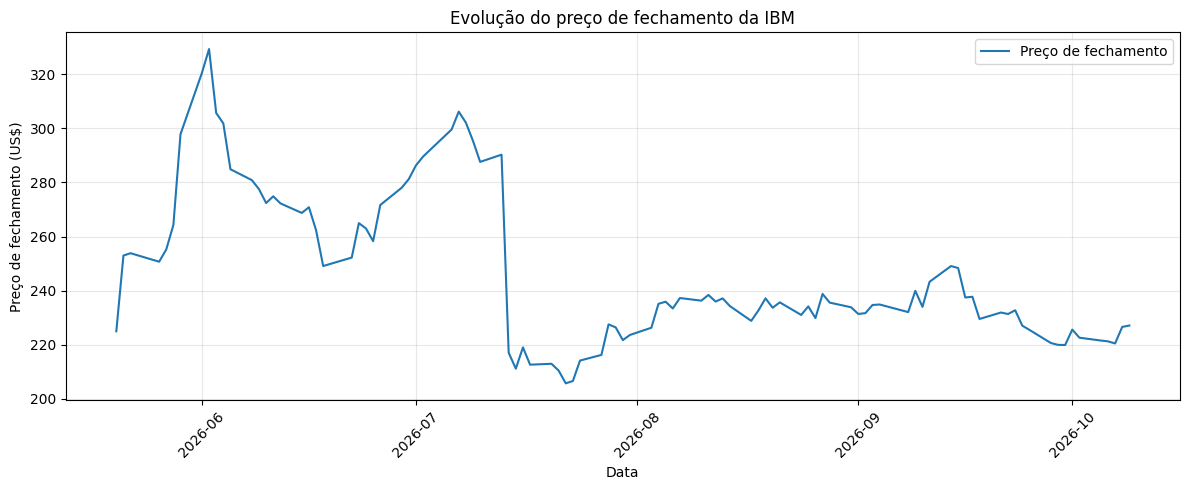

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_stock.index,
    df_stock["close"],
    label="Preço de fechamento"
)

plt.title("Evolução do preço de fechamento da IBM")
plt.xlabel("Data")
plt.ylabel("Preço de fechamento (US$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# GRÁFICO 2 - Matriz de confusão visual

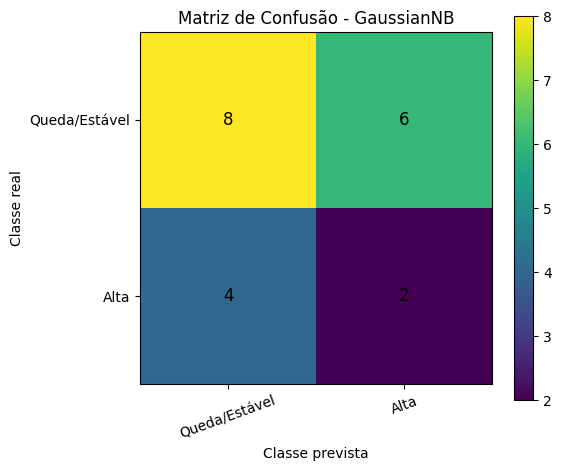

In [19]:
plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation="nearest")
plt.title("Matriz de Confusão - GaussianNB")
plt.colorbar()

classes = ["Queda/Estável", "Alta"]

plt.xticks([0, 1], classes, rotation=20)
plt.yticks([0, 1], classes)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=12
        )

plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()


# GRÁFICO 3 - Comparação entre classes reais e previstas

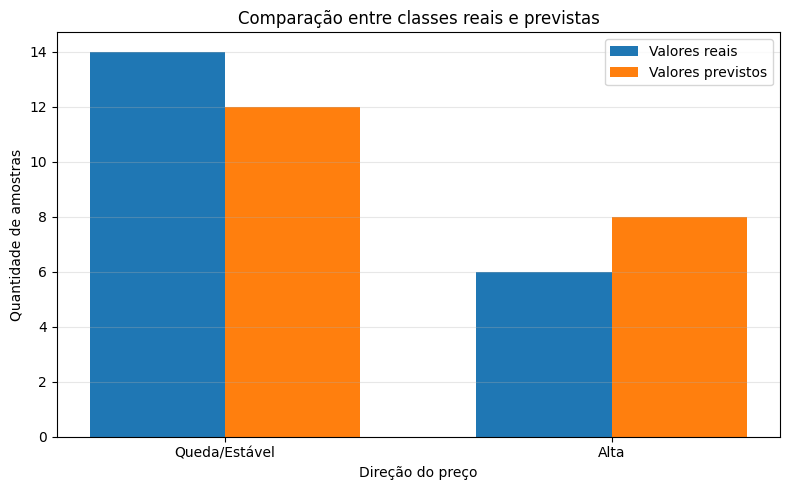

In [20]:
quantidade_real = [
    int(np.sum(y_test == 0)),
    int(np.sum(y_test == 1))
]

quantidade_prevista = [
    int(np.sum(y_pred_stock == 0)),
    int(np.sum(y_pred_stock == 1))
]

posicoes = np.arange(2)
largura = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    posicoes - largura / 2,
    quantidade_real,
    largura,
    label="Valores reais"
)

plt.bar(
    posicoes + largura / 2,
    quantidade_prevista,
    largura,
    label="Valores previstos"
)

plt.title("Comparação entre classes reais e previstas")
plt.xlabel("Direção do preço")
plt.ylabel("Quantidade de amostras")
plt.xticks(posicoes, ["Queda/Estável", "Alta"])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


##Por que a premissa de shuffle=False é imprescindível em séries temporais financeiras para evitar vazamento de dados futuros (data leakage)?

>A utilização de shuffle=False é obrigatória em séries temporais financeiras para preservar a ordem cronológica dos dados, respeitando a sequência temporal dos eventos de mercado. O embaralhamento incorreto alocaria dados futuros no conjunto de treinamento e dados passados no conjunto de teste, provocando data leakage (vazamento de dados). Isso gera métricas de desempenho inflacionadas e irreais, pois o modelo "anteciparia" informações que não estariam disponíveis no momento da predição real. Mantendo shuffle=False, garante-se que o modelo seja treinado exclusivamente com o comportamento histórico e avaliado em períodos posteriores, simulando de forma fidedigna o cenário real de previsão de mercado.

